# CMPSC 105 — College Cost and Payoff

**Team members:** Artemii Otbliesk
**Dataset:** `college_scorecard.csv`  
**Research question:** How do college net price, student debt, completion, and later earnings differ by institution type and school size? Does higher price predict better outcomes?

> **Setup:** Put `college_scorecard.csv` in the same repository folder as this notebook. Do **not** upload the CSV to GitHub. Run each code cell in order using the `.venv` Python kernel.


## 1. Import libraries and load relevant data

The original dataset is very wide. Read only the columns we need for this question.

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
DATA_FILE = Path("college_scorecard.csv")
assert DATA_FILE.exists(), "Put college_scorecard.csv in the same folder as analysis.ipynb"

columns = [
    "UNITID", "INSTNM", "CONTROL", "PREDDEG", "CURROPER", "UGDS",
    "NPT4_PUB", "NPT4_PRIV", "DEBT_MDN", "C150_4", "C150_L4",
    "MD_EARN_WNE_P10", "ADM_RATE",
]
raw = pd.read_csv(DATA_FILE, usecols=columns, low_memory=False)
print(f"Original data: {len(raw):,} schools, {len(raw.columns)} selected columns")
raw.head()


Original data: 6,273 schools, 13 selected columns


,UNITID,INSTNM,PREDDEG,CONTROL,ADM_RATE,UGDS,CURROPER,NPT4_PUB,NPT4_PRIV,C150_4,C150_L4,DEBT_MDN,MD_EARN_WNE_P10
0,100654,Alabama A & M University,3,1,0.5795,6124.0,1,17621.0,NaN,0.2403,NaN,16600,40628.0
1,100663,University of Alabama at Birmingham,3,1,0.8818,11635.0,1,18749.0,NaN,0.6423,NaN,15832,54501.0
2,100690,Amridge University,3,2,NaN,241.0,1,NaN,NaN,1.0000,NaN,13385,37621.0
3,100706,University of Alabama in Huntsville,3,1,0.6857,6591.0,1,18796.0,NaN,0.6429,NaN,13905,61767.0
4,100724,Alabama State University,3,1,0.9755,3477.0,1,20435.0,NaN,0.3034,NaN,17500,34502.0


## 2. Explore missing and suppressed earnings data

`MD_EARN_WNE_P10` is median earnings **10 years after entry**, not necessarily 10 years after graduation. `PS` is the College Scorecard privacy-suppression code; blanks also count as unavailable earnings.

In [3]:
earnings_text = raw["MD_EARN_WNE_P10"].astype("string").str.strip()
explicit_ps = earnings_text.str.upper().eq("PS").fillna(False).sum()
blank_earnings = earnings_text.isna().sum() + earnings_text.eq("").fillna(False).sum()
print(f"All institutions: {len(raw):,}")
print(f"Blank earnings values: {blank_earnings:,}")
print(f"Explicit 'PS' earnings values: {explicit_ps:,}")
print(f"Total earnings unavailable: {blank_earnings + explicit_ps:,}")


All institutions: 6,273
Blank earnings values: 1,146
Explicit 'PS' earnings values: 0
Total earnings unavailable: 1,146


## 3. Clean and categorize institutions

- Keep active institutions with undergraduate students and certificate/associate/bachelor's offerings.
- Public uses `NPT4_PUB` and private institutions use `NPT4_PRIV` for annual net price.
- Completion uses `C150_4` for bachelor's schools, `C150_L4` for shorter-program schools.
- Medians are **across institutions**, not weighted by enrollment.

In [4]:
df = raw.copy()
for col in columns:
    if col != "INSTNM":
        df[col] = pd.to_numeric(df[col], errors="coerce")

df = df.loc[
    (df["CURROPER"] == 1)
    & (df["UGDS"] > 0)
    & (df["PREDDEG"].isin([1, 2, 3]))
    & (df["CONTROL"].isin([1, 2, 3]))
].copy()

type_order = ["Public", "Private nonprofit", "For-profit"]
size_order = ["Small (<1k)", "Medium (1-5k)", "Large (5-15k)", "Very large (15k+)"]
df["school_type"] = df["CONTROL"].map({1: "Public", 2: "Private nonprofit", 3: "For-profit"})
df["credential"] = df["PREDDEG"].map({1: "Certificate", 2: "Associate", 3: "Bachelor"})
df["school_size"] = pd.cut(df["UGDS"], bins=[0, 1000, 5000, 15000, np.inf],
                           labels=size_order, right=False)
df["net_price"] = np.where(df["CONTROL"] == 1, df["NPT4_PUB"], df["NPT4_PRIV"])
df.loc[df["net_price"] < 0, "net_price"] = np.nan

df["student_debt"] = df["DEBT_MDN"]
df["earnings_10yr"] = df["MD_EARN_WNE_P10"]
df["completion_rate"] = np.where(df["PREDDEG"] == 3, df["C150_4"], df["C150_L4"])
df.loc[~df["completion_rate"].between(0, 1), "completion_rate"] = np.nan
print(f"Analysis sample: {len(df):,} schools")
df[["INSTNM", "school_type", "school_size", "net_price", "student_debt", "completion_rate", "earnings_10yr"]].head()


Analysis sample: 5,445 schools


,INSTNM,school_type,school_size,net_price,student_debt,completion_rate,earnings_10yr
0,Alabama A & M University,Public,Large (5-15k),17621.0,16600.0,0.2403,40628.0
1,University of Alabama at Birmingham,Public,Large (5-15k),18749.0,15832.0,0.6423,54501.0
2,Amridge University,Private nonprofit,Small (<1k),NaN,13385.0,1.0000,37621.0
3,University of Alabama in Huntsville,Public,Large (5-15k),18796.0,13905.0,0.6429,61767.0
4,Alabama State University,Public,Medium (1-5k),20435.0,17500.0,0.3034,34502.0


## 4. Compare public, nonprofit, and for-profit institutions

In [5]:
by_type = (
    df.groupby("school_type", observed=True)
      .agg(schools=("UNITID", "size"),
           annual_net_price=("net_price", "median"),
           median_debt=("student_debt", "median"),
           completion_rate=("completion_rate", "median"),
           earnings_10yr=("earnings_10yr", "median"),
           schools_with_earnings=("earnings_10yr", "count"))
      .reindex(type_order)
)
by_type["schools_missing_earnings"] = by_type["schools"] - by_type["schools_with_earnings"]
by_type.round(2)


,schools,annual_net_price,median_debt,completion_rate,earnings_10yr,schools_with_earnings,schools_missing_earnings
school_type,,,,,,,
Public,1887,10206.0,8729.5,0.46,42379.0,1818,69
Private nonprofit,1525,22227.0,16000.0,0.59,53160.0,1302,223
For-profit,2033,20287.0,8257.5,0.71,29839.0,1533,500


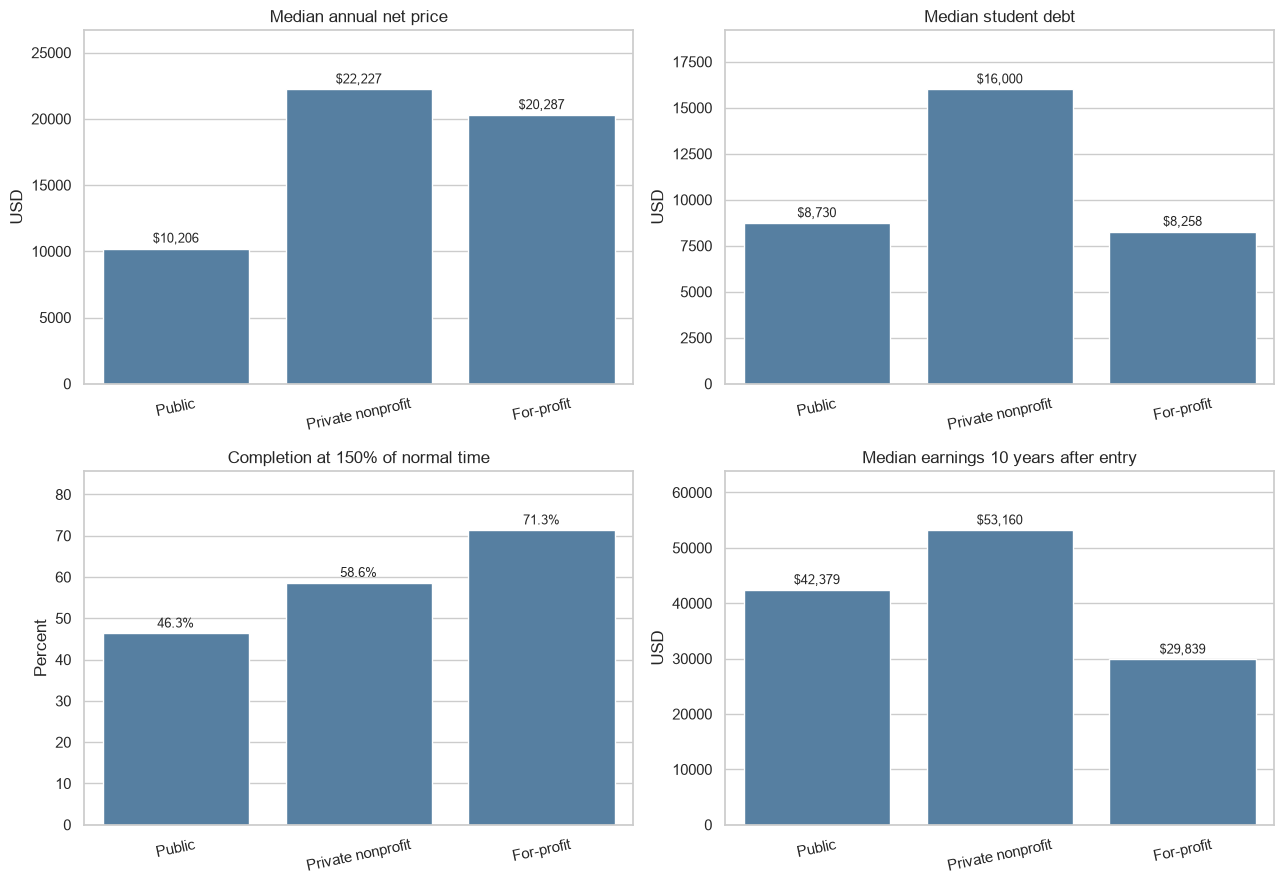

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plots = [
    ("annual_net_price", "Median annual net price", "USD", 1),
    ("median_debt", "Median student debt", "USD", 1),
    ("completion_rate", "Completion at 150% of normal time", "Percent", 100),
    ("earnings_10yr", "Median earnings 10 years after entry", "USD", 1),
]
for ax, (key, title, ylabel, multiplier) in zip(axes.flat, plots):
    data = by_type[key] * multiplier
    sns.barplot(x=data.index, y=data.values, ax=ax, color="#4a80ad")
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(ylabel)
    ax.tick_params(axis="x", rotation=12)
    ax.set_ylim(0, data.max() * 1.2)
    for index, value in enumerate(data.values):
        label = f"{value:.1f}%" if multiplier == 100 else f"${value:,.0f}"
        ax.text(index, value + data.max() * 0.02, label, ha="center", fontsize=9)
plt.tight_layout()
plt.show()


## 5. Compare by size (and school type)

Size categories are based on undergraduate enrollment. Remember that group size and degree offerings may vary substantially.

In [8]:
by_size = (
    df.groupby(["school_type", "school_size"], observed=True)
      .agg(schools=("UNITID", "size"),
           annual_net_price=("net_price", "median"),
           median_debt=("student_debt", "median"),
           completion_rate=("completion_rate", "median"),
           earnings_10yr=("earnings_10yr", "median"))
      .reset_index()
)
by_size.round(2)


,school_type,school_size,schools,annual_net_price,median_debt,completion_rate,earnings_10yr
0,For-profit,Small (<1k),1885,19921.5,7917.0,0.72,28707.0
1,For-profit,Medium (1-5k),125,28112.0,10010.0,0.63,40092.0
2,For-profit,Large (5-15k),16,21156.0,12086.0,0.33,38696.0
3,For-profit,Very large (15k+),7,16745.0,12166.0,0.21,38219.0
4,Private nonprofit,Small (<1k),850,19971.0,13500.0,0.50,46566.0
5,Private nonprofit,Medium (1-5k),571,23873.5,18500.0,0.64,56950.0
6,Private nonprofit,Large (5-15k),89,30902.0,17924.0,0.80,76054.0
7,Private nonprofit,Very large (15k+),15,29927.5,14250.0,0.81,68202.5
8,Public,Small (<1k),527,9964.0,8550.0,0.61,39477.0
9,Public,Medium (1-5k),736,9329.0,8000.0,0.40,40278.0


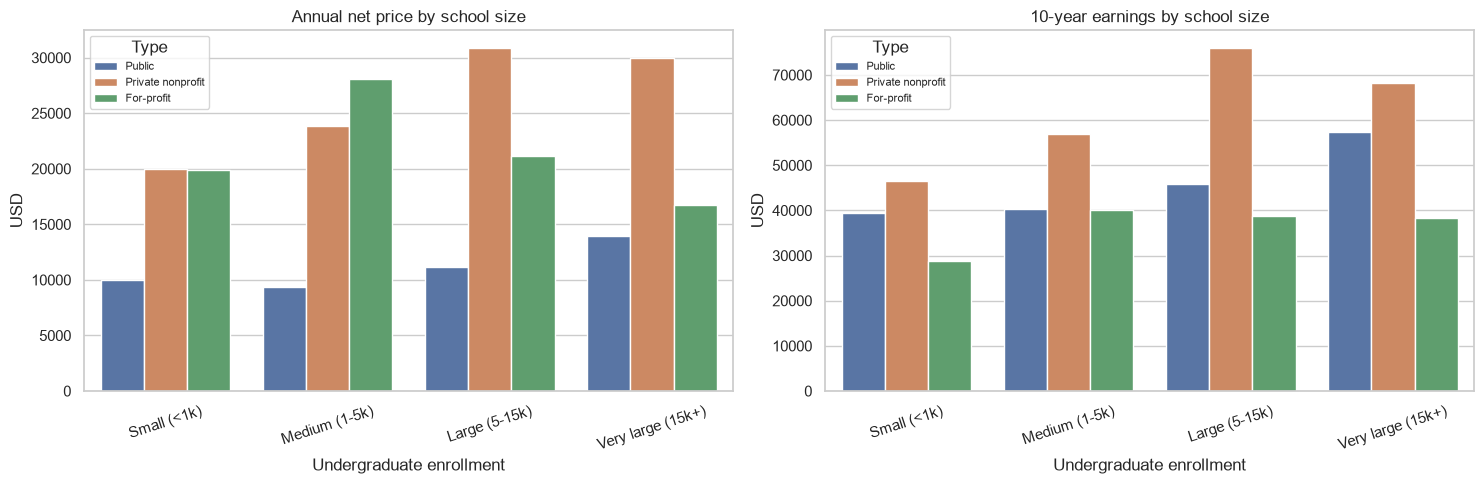

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, column, title in [
    (axes[0], "annual_net_price", "Annual net price by school size"),
    (axes[1], "earnings_10yr", "10-year earnings by school size"),
]:
    sns.barplot(data=by_size, x="school_size", y=column,
                hue="school_type", order=size_order, hue_order=type_order,
                errorbar=None, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Undergraduate enrollment")
    ax.set_ylabel("USD")
    ax.tick_params(axis="x", rotation=18)
    ax.legend(title="Type", fontsize=8)
plt.tight_layout()
plt.show()


## 6. Does a more expensive school pay off?

Compare high-cost vs low-cost schools **within the same type, degree focus, and size category**. Each group needs at least 40 schools with complete data. This is observational evidence, not proof that higher price causes higher earnings.

In [10]:
complete = df.dropna(subset=["net_price", "earnings_10yr", "student_debt", "completion_rate"])
rows = []
for (kind, degree, size), group in complete.groupby(
    ["school_type", "credential", "school_size"], observed=True
):
    if len(group) < 40:
        continue
    midpoint = group["net_price"].median()
    cheaper = group[group["net_price"] <= midpoint]
    pricier = group[group["net_price"] > midpoint]
    if min(len(cheaper), len(pricier)) < 20:
        continue
    rows.append({
        "school_type": kind,
        "credential": degree,
        "school_size": str(size),
        "schools": len(group),
        "additional_annual_price": pricier["net_price"].median() - cheaper["net_price"].median(),
        "additional_annual_earnings": pricier["earnings_10yr"].median() - cheaper["earnings_10yr"].median(),
        "completion_change_pp": (pricier["completion_rate"].median() - cheaper["completion_rate"].median()) * 100,
        "additional_debt": pricier["student_debt"].median() - cheaper["student_debt"].median(),
    })
price_comparison = pd.DataFrame(rows)
price_comparison.sort_values("additional_annual_earnings", ascending=False).round(1)


,school_type,credential,school_size,schools,additional_annual_price,additional_annual_earnings,completion_change_pp,additional_debt
11,Public,Bachelor,Small (<1k),44,7907.5,12437.0,-2.4,6922.5
1,For-profit,Bachelor,Small (<1k),47,11169.0,10904.5,11.5,2961.0
15,Public,Certificate,Small (<1k),136,9906.0,7740.5,21.7,2990.5
5,Private nonprofit,Bachelor,Medium (1-5k),535,8885.5,7629.5,11.3,1999.5
2,For-profit,Certificate,Small (<1k),1009,8397.5,6383.0,-3.7,1950.0
12,Public,Bachelor,Medium (1-5k),194,5974.0,6361.0,10.4,2694.0
0,For-profit,Associate,Small (<1k),55,13040.0,5704.5,-4.0,1958.5
13,Public,Bachelor,Large (5-15k),195,5698.0,4671.0,6.0,2104.0
4,Private nonprofit,Bachelor,Small (<1k),350,8686.0,3711.0,6.0,1313.0
6,Private nonprofit,Bachelor,Large (5-15k),84,16657.5,3427.5,8.0,5053.5


## 7. Missing earnings by school type

A missing earnings figure is not a zero earning. Explicit privacy suppression and blank/unavailable cells should be reported separately when the raw data allows it.

In [11]:
missing_by_type = df.groupby("school_type", observed=True).agg(
    schools=("UNITID", "size"),
    schools_with_earnings=("earnings_10yr", "count"),
).reindex(type_order)
missing_by_type["missing_earnings"] = missing_by_type["schools"] - missing_by_type["schools_with_earnings"]
missing_by_type["percent_missing"] = 100 * missing_by_type["missing_earnings"] / missing_by_type["schools"]
print("Missing/suppressed earnings in original data:", int(blank_earnings + explicit_ps))
print("Missing/suppressed earnings in analysis sample:", int(df["earnings_10yr"].isna().sum()))
missing_by_type.round(1)


Missing/suppressed earnings in original data: 1146
Missing/suppressed earnings in analysis sample: 792


,schools,schools_with_earnings,missing_earnings,percent_missing
school_type,,,,
Public,1887,1818,69,3.7
Private nonprofit,1525,1302,223,14.6
For-profit,2033,1533,500,24.6


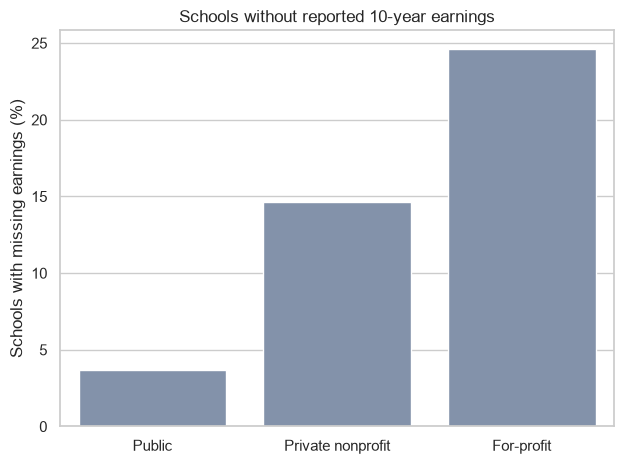

In [12]:
sns.barplot(data=missing_by_type.reset_index(), x="school_type", y="percent_missing", color="#7d91b0")
plt.title("Schools without reported 10-year earnings")
plt.xlabel("")
plt.ylabel("Schools with missing earnings (%)")
plt.tight_layout()
plt.show()


## 8. Write findings (complete after reviewing tables/plots)

**School type:** Which institutions have the lowest annual net price, lowest median debt, highest completion, and highest earnings? Cite actual numbers.

**School size:** Which size categories perform differently? Are the differences similar for public/nonprofit/for-profit schools?

**Where cost appears worthwhile:** Identify one within-group comparison where higher net price goes with meaningfully better earnings or completion. Quote the extra price and extra earnings.

**Where it does not:** Identify one within-group comparison with little or no earnings advantage, lower completion, or higher debt.

**Missingness and limitations:** Count missing earnings for the full data and analysis sample. Mention unavailable values can bias comparisons. Note that institution-level results don't account for student backgrounds, major, location or selection effects, and the dataset's 10-year earnings measure is after **entry**.
